In [15]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
FIGURES_DIR = PROJECT_ROOT / "artifacts" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Project root
PROJECT_ROOT = Path.cwd().parent

# Dataset path
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "heart_disease_raw.csv"

# Load dataset
df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded from: {DATA_PATH}")
print(f"Shape: {df.shape}")

df.head()

Dataset loaded from: c:\Users\Pavithra\mlops-heart-disease\data\raw\heart_disease_raw.csv
Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [2]:
print("Dataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Dataset shape:
(303, 14)

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

Data types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
num           int64
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null

In [3]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": (missing_values / len(df) * 100).round(2)
})

missing_summary = missing_summary[missing_summary["Missing Count"] > 0]

missing_summary

,Missing Count,Missing Percentage
ca,4,1.32
thal,2,0.66


In [4]:
duplicate_count = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [6]:
categorical_columns = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

for column in categorical_columns:
    print(f"\n{'=' * 50}")
    print(f"{column}")
    print(f"{'=' * 50}")
    print(df[column].value_counts(dropna=False).sort_index())


sex
sex
0     97
1    206
Name: count, dtype: int64

cp
cp
1     23
2     50
3     86
4    144
Name: count, dtype: int64

fbs
fbs
0    258
1     45
Name: count, dtype: int64

restecg
restecg
0    151
1      4
2    148
Name: count, dtype: int64

exang
exang
0    204
1     99
Name: count, dtype: int64

slope
slope
1    142
2    140
3     21
Name: count, dtype: int64

ca
ca
0.0    176
1.0     65
2.0     38
3.0     20
NaN      4
Name: count, dtype: int64

thal
thal
3.0    166
6.0     18
7.0    117
NaN      2
Name: count, dtype: int64


In [7]:
target_counts = df["num"].value_counts().sort_index()

print("Original target distribution:")
print(target_counts)

target_percentages = (
    df["num"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\nTarget percentages:")
print(target_percentages)

Original target distribution:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Target percentages:
num
0    54.13
1    18.15
2    11.88
3    11.55
4     4.29
Name: proportion, dtype: float64


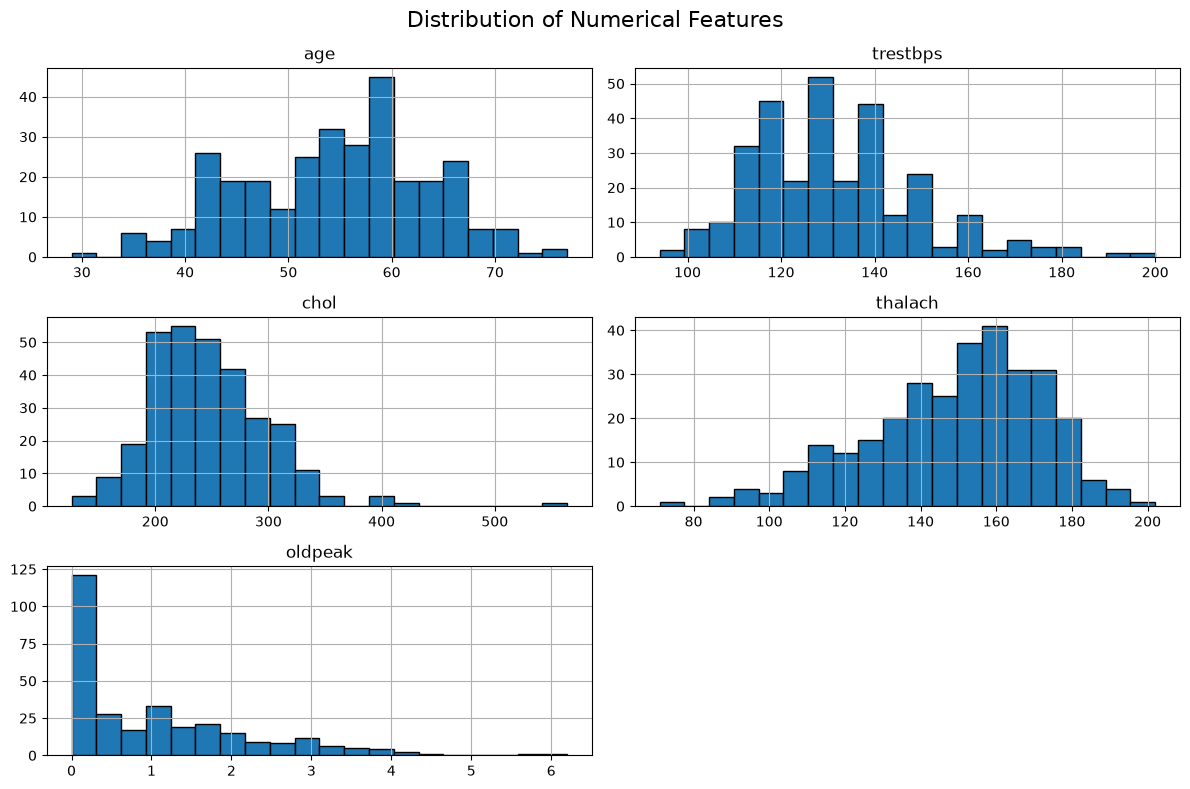

In [8]:
numerical_columns = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

df[numerical_columns].hist(
    bins=20,
    figsize=(12, 8),
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

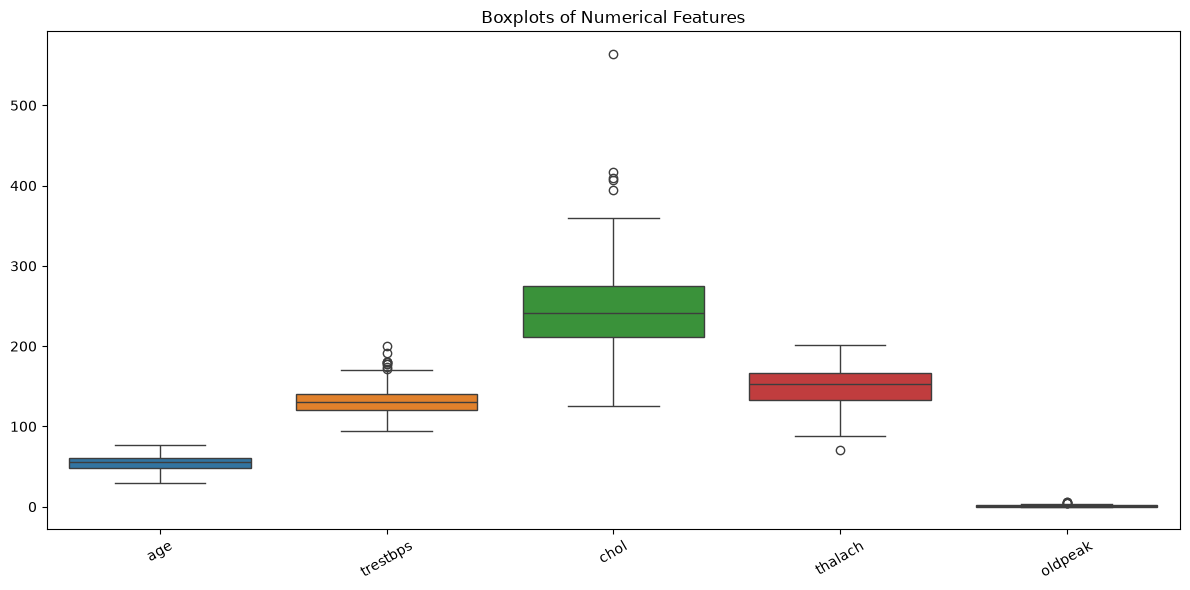

In [9]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df[numerical_columns])

plt.title("Boxplots of Numerical Features")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

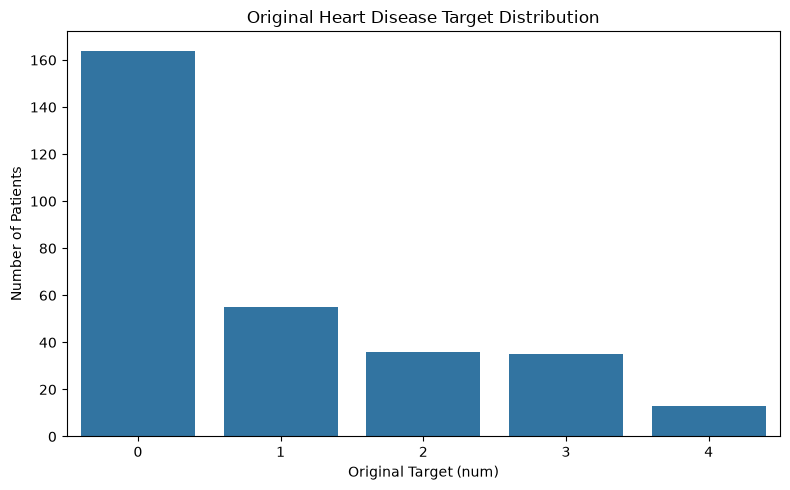

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="num")

plt.title("Original Heart Disease Target Distribution")
plt.xlabel("Original Target (num)")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

In [11]:
df_binary = df.copy()

df_binary["target"] = (df_binary["num"] > 0).astype(int)

# Remove the original multiclass target
df_binary = df_binary.drop(columns=["num"])

print("Binary target distribution:")
print(df_binary["target"].value_counts().sort_index())

Binary target distribution:
target
0    164
1    139
Name: count, dtype: int64


In [12]:
binary_target_percentage = (
    df_binary["target"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("Binary target percentages:")
print(binary_target_percentage)

Binary target percentages:
target
0    54.13
1    45.87
Name: proportion, dtype: float64


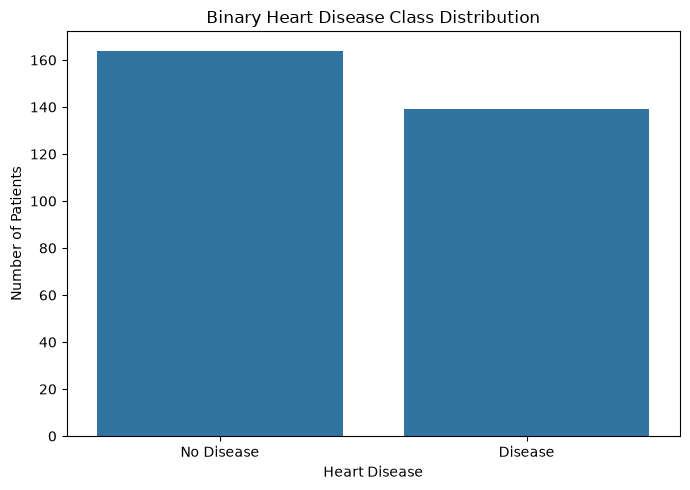

In [13]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df_binary, x="target")

plt.title("Binary Heart Disease Class Distribution")
plt.xlabel("Heart Disease")
plt.ylabel("Number of Patients")

ax.set_xticks([0, 1])
ax.set_xticklabels(["No Disease", "Disease"])

plt.tight_layout()
plt.show()

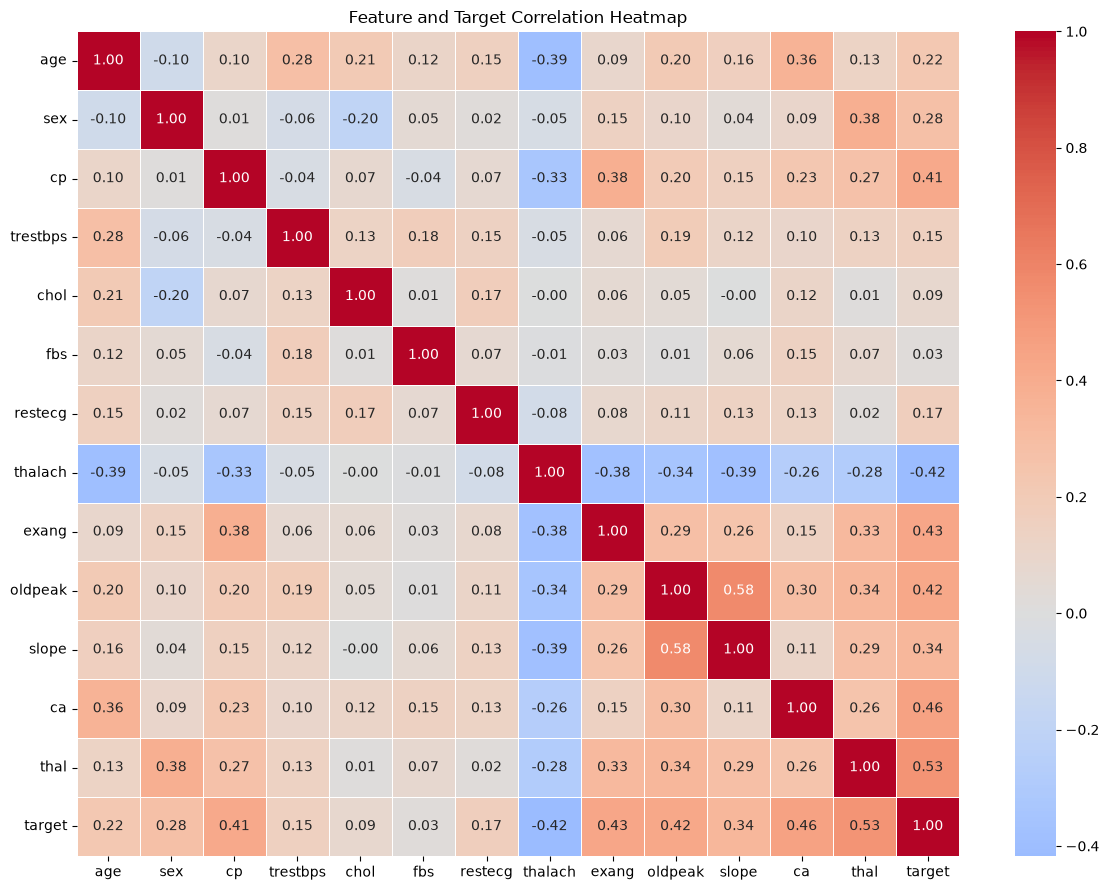

In [14]:
plt.figure(figsize=(12, 9))

correlation_matrix = df_binary.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Feature and Target Correlation Heatmap")
plt.tight_layout()
plt.show()

## EDA Findings

- The dataset contains 303 observations and 14 columns, including 13 input features and the original target variable `num`.
- No duplicate records were identified.
- Missing values were found in `ca` (4 records, 1.32%) and `thal` (2 records, 0.66%).
- Numerical features show different scales and distributions, with some potential statistical outliers in cholesterol, resting blood pressure, and oldpeak.
- Potential outliers were retained because they may represent valid patient measurements.
- The original target variable contains five values (0–4).
- For binary classification, target values were transformed as follows:
  - 0 → No disease
  - 1–4 → Disease
- The resulting binary target contains 164 no-disease cases (54.13%) and 139 disease cases (45.87%).
- The binary target is reasonably balanced.
- Correlation analysis suggests associations between the target and features such as thal, ca, exang, oldpeak, cp, and thalach. However, correlation was not used as the sole criterion for feature selection because several variables are categorical codes.

## Feature Engineering and Train/Test Split

In [16]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df_binary.drop(columns=["target"])
y = df_binary["target"]

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True).sort_index())

Training set shape: (242, 13)
Test set shape: (61, 13)

Training target distribution:
target
0    0.541322
1    0.458678
Name: proportion, dtype: float64

Test target distribution:
target
0    0.540984
1    0.459016
Name: proportion, dtype: float64


In [17]:
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak",
    "ca"
]

categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "thal"
]

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
Categorical features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing
numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [19]:
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

print("Logistic Regression pipeline created.")

Logistic Regression pipeline created.


In [22]:
logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [20]:
from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("Random Forest pipeline created.")

Random Forest pipeline created.


In [21]:
random_forest_pipeline.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
)


def evaluate_model(model, X_test, y_test, model_name):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
    }

    return metrics

In [24]:
logistic_results = evaluate_model(
    logistic_pipeline,
    X_test,
    y_test,
    "Logistic Regression"
)

rf_results = evaluate_model(
    random_forest_pipeline,
    X_test,
    y_test,
    "Random Forest"
)

results = pd.DataFrame([
    logistic_results,
    rf_results
])

results

,Model,Accuracy,Precision,Recall,ROC-AUC
0,Logistic Regression,0.868852,0.81250,0.928571,0.957792
1,Random Forest,0.885246,0.83871,0.928571,0.941017


## Cross-Validation and Hyperparameter Tuning

In [25]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "roc_auc": "roc_auc"
}

In [26]:
logistic_cv = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

logistic_cv_results = {
    "Model": "Logistic Regression",
    "Accuracy Mean": logistic_cv["test_accuracy"].mean(),
    "Accuracy Std": logistic_cv["test_accuracy"].std(),
    "Precision Mean": logistic_cv["test_precision"].mean(),
    "Recall Mean": logistic_cv["test_recall"].mean(),
    "ROC-AUC Mean": logistic_cv["test_roc_auc"].mean()
}

logistic_cv_results

{'Model': 'Logistic Regression',
 'Accuracy Mean': np.float64(0.8470238095238095),
 'Accuracy Std': np.float64(0.021594956566396217),
 'Precision Mean': np.float64(0.8783262504086302),
 'Recall Mean': np.float64(0.7837944664031621),
 'ROC-AUC Mean': np.float64(0.9064947130164521)}

In [27]:
rf_cv = cross_validate(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

rf_cv_results = {
    "Model": "Random Forest",
    "Accuracy Mean": rf_cv["test_accuracy"].mean(),
    "Accuracy Std": rf_cv["test_accuracy"].std(),
    "Precision Mean": rf_cv["test_precision"].mean(),
    "Recall Mean": rf_cv["test_recall"].mean(),
    "ROC-AUC Mean": rf_cv["test_roc_auc"].mean()
}

rf_cv_results

{'Model': 'Random Forest',
 'Accuracy Mean': np.float64(0.8137755102040817),
 'Accuracy Std': np.float64(0.03580022863098789),
 'Precision Mean': np.float64(0.8201831304604221),
 'Recall Mean': np.float64(0.7648221343873518),
 'ROC-AUC Mean': np.float64(0.8865992702949225)}

In [28]:
cv_results = pd.DataFrame([
    logistic_cv_results,
    rf_cv_results
])

cv_results

,Model,Accuracy Mean,Accuracy Std,Precision Mean,Recall Mean,ROC-AUC Mean
0,Logistic Regression,0.847024,0.021595,0.878326,0.783794,0.906495
1,Random Forest,0.813776,0.035800,0.820183,0.764822,0.886599


In [29]:
from sklearn.model_selection import GridSearchCV

logistic_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["liblinear", "lbfgs"]
}

logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)

logistic_grid.fit(X_train, y_train)

print("Best Logistic Regression parameters:")
print(logistic_grid.best_params_)

print("\nBest Logistic Regression CV ROC-AUC:")
print(logistic_grid.best_score_)

Best Logistic Regression parameters:
{'classifier__C': 0.1, 'classifier__solver': 'liblinear'}

Best Logistic Regression CV ROC-AUC:
0.9116938616938619


In [30]:
rf_param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 5, 10],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

rf_grid = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=rf_param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(rf_grid.best_params_)

print("\nBest Random Forest CV ROC-AUC:")
print(rf_grid.best_score_)

Best Random Forest parameters:
{'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}

Best Random Forest CV ROC-AUC:
0.8985372115806898


In [36]:
# Evaluate the tuned models on the untouched test set

tuned_logistic_results = evaluate_model(
    logistic_grid.best_estimator_,
    X_test,
    y_test,
    "Tuned Logistic Regression"
)

tuned_rf_results = evaluate_model(
    rf_grid.best_estimator_,
    X_test,
    y_test,
    "Tuned Random Forest"
)

final_test_results = pd.DataFrame([
    tuned_logistic_results,
    tuned_rf_results
])

final_test_results
final_test_results.to_csv(
    PROJECT_ROOT / "artifacts" / "final_model_results.csv",
    index=False
)

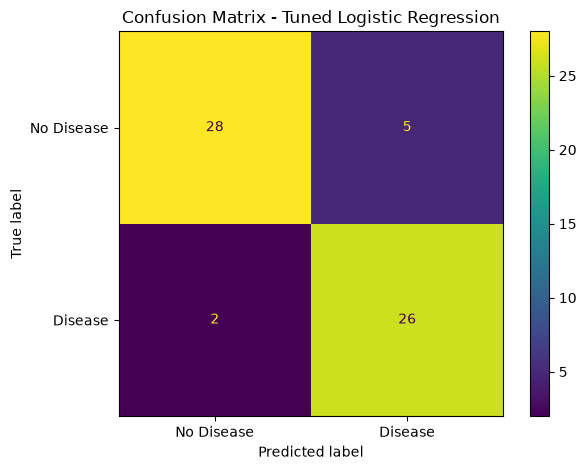

In [34]:
from sklearn.metrics import ConfusionMatrixDisplay

best_model = logistic_grid.best_estimator_

ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    display_labels=["No Disease", "Disease"]
)

plt.title("Confusion Matrix - Tuned Logistic Regression")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "confusion_matrix_logistic_regression.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

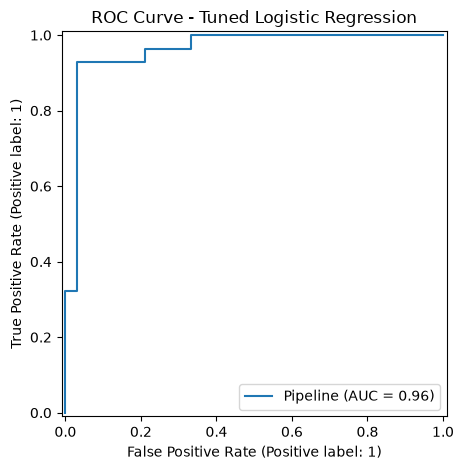

In [35]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(
    logistic_grid.best_estimator_,
    X_test,
    y_test
)

plt.title("ROC Curve - Tuned Logistic Regression")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "roc_curve_logistic_regression.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()